# Análise local dos resultados de teste
Execute todas as células em ordem. CPU é suficiente. Requer pandas, numpy e matplotlib (`%pip install pandas numpy matplotlib` se necessário).

O CSV consolidado deve estar em `reports/results/test_summary.csv`. Matrizes são procuradas em `reports/`, inclusive dentro de ZIPs. As figuras são salvas em PNG e PDF. Ausência de matrizes não impede as duas primeiras figuras.

In [13]:
from pathlib import Path
import io
import re
import zipfile
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        if (folder / "reports" / "results" / "test_summary.csv").is_file():
            return folder

    raise FileNotFoundError(
        "Não encontrei reports/results/test_summary.csv. "
        "Adicione o consolidado ao repositório ou defina ROOT manualmente."
    )

ROOT = find_repo_root()

SUMMARY_PATH = ROOT / "reports/results/test_summary.csv"
FIGURES = ROOT / "reports/figures"
TABLES = ROOT / "reports/results"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print("Repositório:", ROOT)
print("Tabela:", SUMMARY_PATH)
print("Figuras:", FIGURES)
from IPython.display import display
GENERATED = []


Repositório: C:\Users\paula\OneDrive\Documentos\Deep Learning\Deep-Learning-in-OCT-classification
Tabela: C:\Users\paula\OneDrive\Documentos\Deep Learning\Deep-Learning-in-OCT-classification\reports\results\test_summary.csv
Figuras: C:\Users\paula\OneDrive\Documentos\Deep Learning\Deep-Learning-in-OCT-classification\reports\figures


In [14]:
df = pd.read_csv(SUMMARY_PATH)

keys = ["model", "adaptation", "train_fraction_pct", "subset_seed"]
required = keys + [
    "split", "n_test", "macro_f1",
    "accuracy", "balanced_accuracy", "auroc_macro"
]

missing = set(required) - set(df.columns)
assert not missing, f"Colunas ausentes: {sorted(missing)}"

assert len(df) == 29, f"Esperadas 29 avaliações; encontradas {len(df)}."
assert df["split"].eq("test").all()
assert df["n_test"].eq(2797).all()
assert not df.duplicated(keys).any(), "Há execuções repetidas."

for metric in ["macro_f1", "accuracy", "balanced_accuracy", "auroc_macro"]:
    df[metric] = pd.to_numeric(df[metric], errors="raise")
    assert df[metric].between(0, 1).all(), f"Valores inválidos: {metric}"

display(
    df.groupby(["model", "adaptation"])
    .size()
    .rename("avaliacoes")
    .to_frame()
)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
# Registra cada arquivo gerado nesta execução.
def save_figure(fig, name, show=True):
    for extension in ['png', 'pdf']:
        target = FIGURES / f'{name}.{extension}'
        fig.savefig(target, dpi=200, bbox_inches='tight')
        GENERATED.append(target)
    if show:
        display(fig)
    plt.close(fig)


avaliacoes
model         adaptation                    
dinov3_vitl16 linear_probe                13
              partial_finetuning           3
resnet50      linear_probe                13

## 1. Curvas por fração
Barras mostram desvio-padrão amostral, não intervalo de confiança. Em 100% há somente uma execução.

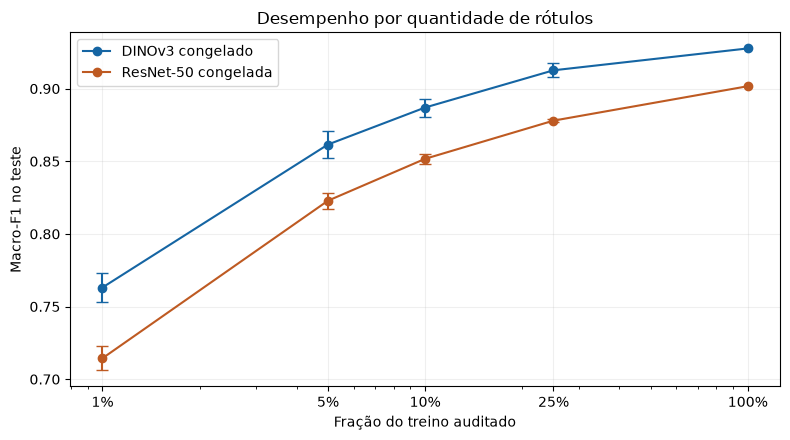

,model,train_fraction_pct,mean,std,count
0,dinov3_vitl16,1,0.763119,0.009761,3
1,dinov3_vitl16,5,0.861541,0.009158,3
2,dinov3_vitl16,10,0.887003,0.006198,3
3,dinov3_vitl16,25,0.912624,0.004941,3
4,dinov3_vitl16,100,0.927680,NaN,1
5,resnet50,1,0.714402,0.008345,3
6,resnet50,5,0.822861,0.005594,3
7,resnet50,10,0.851693,0.003510,3
8,resnet50,25,0.877976,0.001219,3
9,resnet50,100,0.901671,NaN,1


In [15]:
linear = df[df.adaptation.eq('linear_probe')]
curve = linear.groupby(['model','train_fraction_pct']).macro_f1.agg(['mean','std','count']).reset_index()
curve.to_csv(TABLES/'test_learning_curve_summary.csv', index=False)
fig, ax = plt.subplots(figsize=(8,4.5))
for model, label, color in [('dinov3_vitl16','DINOv3 congelado','#1565A3'),('resnet50','ResNet-50 congelada','#BE5A22')]:
    g = curve[curve.model.eq(model)].sort_values('train_fraction_pct')
    ax.plot(g.train_fraction_pct,g['mean'],'o-',label=label,color=color)
    r = g[g['count'] > 1]
    ax.errorbar(r.train_fraction_pct,r['mean'],yerr=r['std'],fmt='none',capsize=4,color=color)
ax.set_xscale('log')
ax.set_xticks([1,5,10,25,100],['1%','5%','10%','25%','100%'])
ax.set(xlabel='Fração do treino auditado',ylabel='Macro-F1 no teste',title='Desempenho por quantidade de rótulos')
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()
save_figure(fig,'test_learning_curve')
display(curve)


## 2. Congelado versus fine-tuning parcial
Comparação pareada de DINOv3 em 10% do treino. Cada linha conecta a mesma semente.

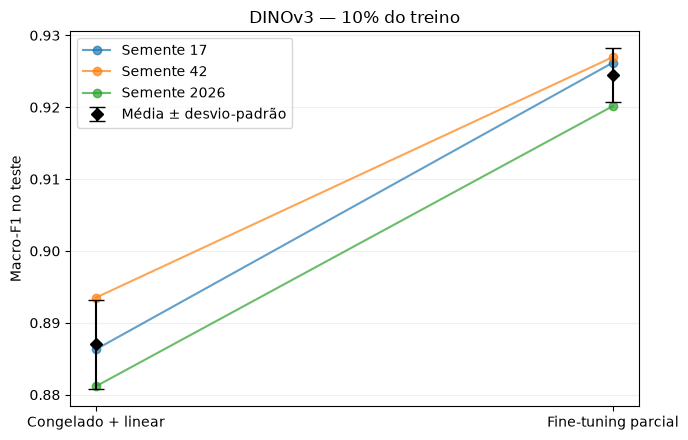

adaptation,linear_probe,partial_finetuning,gain_pp
subset_seed,,,
17,0.886318,0.926215,3.989643
42,0.893515,0.926989,3.347380
2026,0.881177,0.920169,3.899255


Ganho médio: 3.75 pontos percentuais


In [16]:
comparison = df[df.model.eq('dinov3_vitl16') & df.train_fraction_pct.eq(10)]
paired = comparison.pivot(index='subset_seed',columns='adaptation',values='macro_f1').reindex([17,42,2026])
cols = ['linear_probe','partial_finetuning']
assert paired[cols].notna().all().all(), 'Faltam resultados pareados.'
paired['gain_pp'] = 100*(paired.partial_finetuning-paired.linear_probe)
paired.reset_index().to_csv(TABLES/'dinov3_partial_ft_paired_comparison.csv',index=False)
fig, ax = plt.subplots(figsize=(7,4.5))
for seed,row in paired.iterrows():
    ax.plot([0,1],row[cols].to_numpy(), 'o-',alpha=.7,label=f'Semente {seed}')
ax.errorbar([0,1],paired[cols].mean(),yerr=paired[cols].std(ddof=1),fmt='D',color='black',capsize=6,label='Média ± desvio-padrão')
ax.set_xticks([0,1],['Congelado + linear','Fine-tuning parcial'])
ax.set(ylabel='Macro-F1 no teste',title='DINOv3 — 10% do treino')
ax.grid(axis='y',alpha=.2); ax.legend(); fig.tight_layout()
save_figure(fig,'dinov3_frozen_vs_partial_ft')
display(paired)
print(f'Ganho médio: {paired.gain_pp.mean():.2f} pontos percentuais')


## 3. Matrizes de confusão
Busca CSVs extraídos e ZIPs dentro de `reports/`. Associa cada matriz ao caminho da execução registrado no consolidado (incluindo o identificador da configuração), confere suporte e accuracy e ignora cópias idênticas. Não escolhe uma execução diferente apenas porque tem a mesma semente.

Exibe as três primeiras matrizes e salva todas as disponíveis. Consulte o diagnóstico para as ausentes ou inválidas.

Arquivos de matriz encontrados: 61


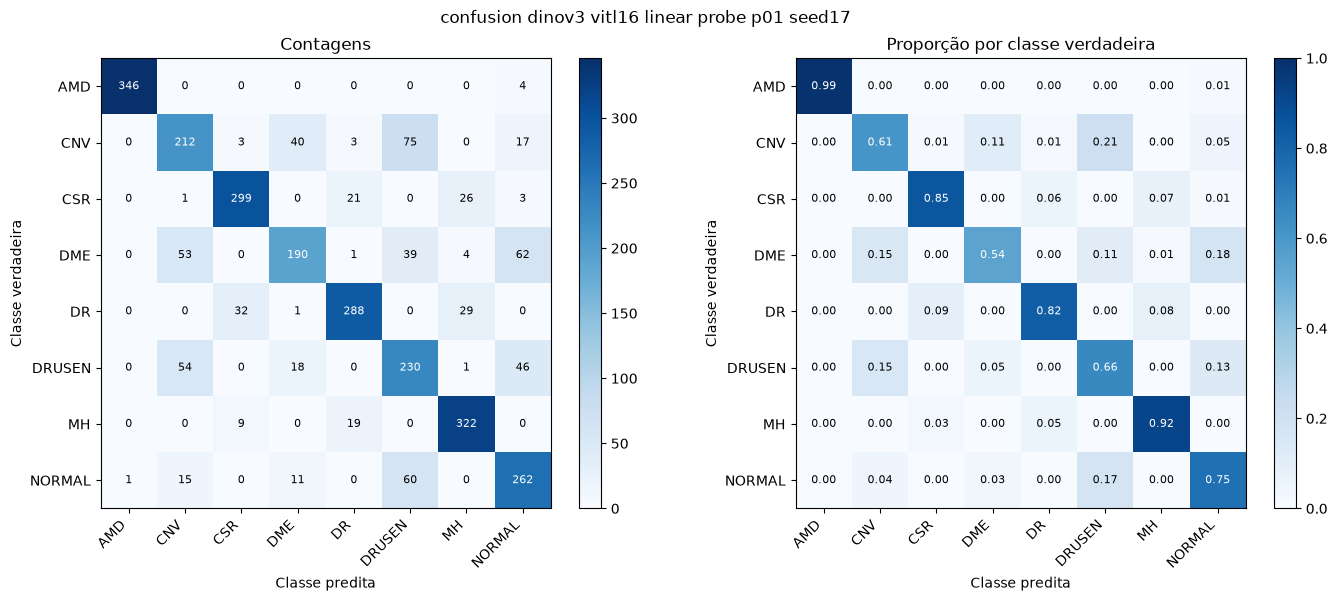

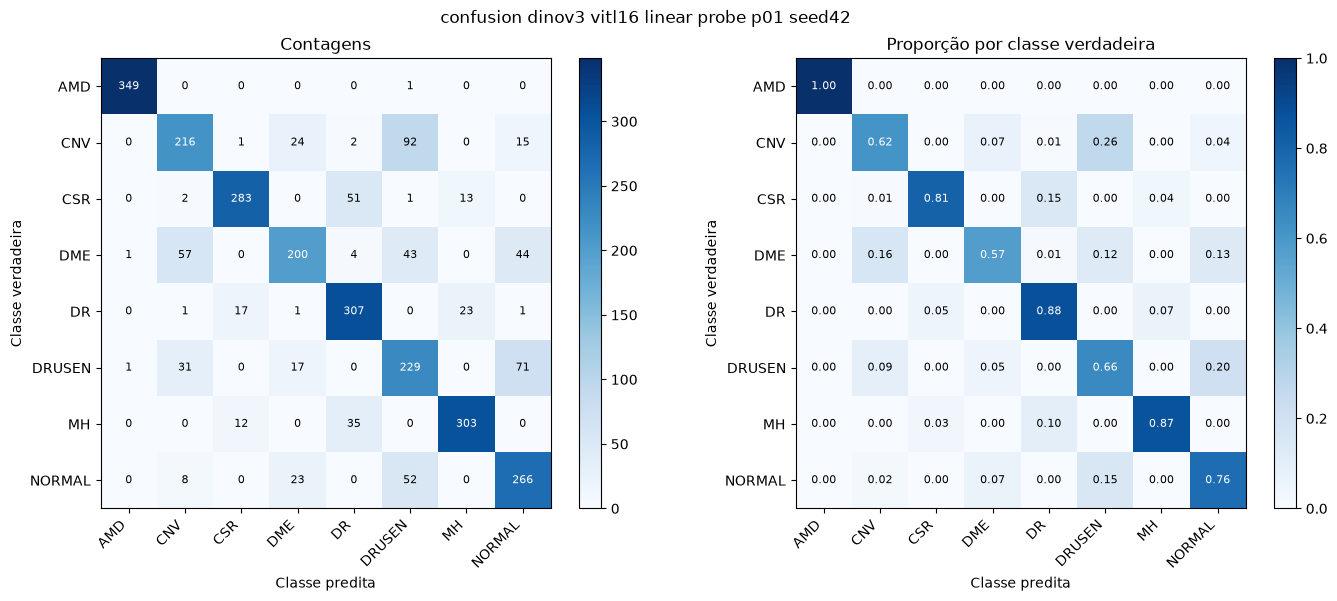

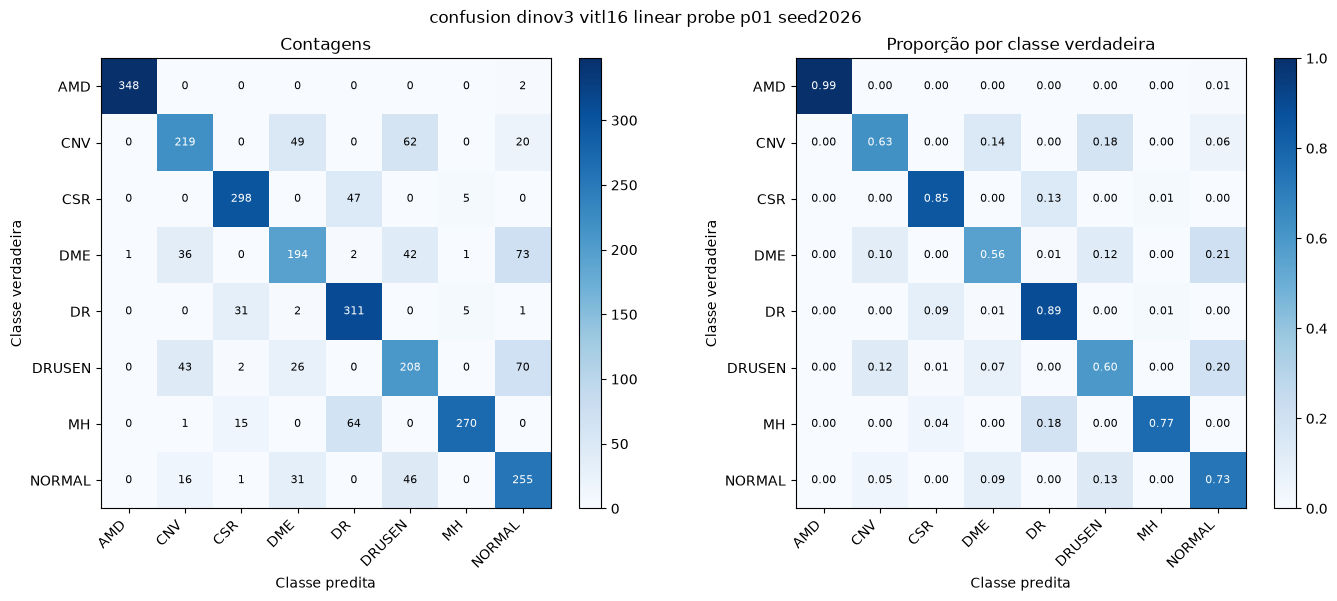

,quantidade
status,
gerada,29


,model,adaptation,train_fraction_pct,subset_seed,status,detail,figure


In [17]:
CLASSES = ['AMD','CNV','CSR','DME','DR','DRUSEN','MH','NORMAL']
SHOW_FIRST = 3

def matrix_sources():
    for path in sorted((ROOT/'reports').rglob('test_confusion_counts.csv')):
        yield path.as_posix(), path.read_bytes()
    for path in sorted((ROOT/'reports').rglob('*.zip')):
        with zipfile.ZipFile(path) as archive:
            for member in archive.namelist():
                if member.endswith('/test_confusion_counts.csv'):
                    yield path.as_posix()+'::'+member, archive.read(member)

def run_suffix(row):
    for field in ['source_run_path','run_path','run','metrics_path']:
        value = row.get(field)
        if pd.isna(value):
            continue
        value = str(value).replace(chr(92),'/')
        match = re.search(r'(p[0-9]+_seed[0-9]+(?:_[0-9a-f]+|/[0-9a-f]+))(?=/|$)',value)
        if match:
            return match.group(1)
    raise ValueError('Não há caminho com identificador de configuração no consolidado.')

sources = list(matrix_sources())
print('Arquivos de matriz encontrados:',len(sources))
records = []
for _,row in df.iterrows():
    record = {k:row[k] for k in keys}
    try:
        suffix = run_suffix(row)
        matches = [(s,b) for s,b in sources if '/'+suffix+'/test_confusion_counts.csv' in '/'+s]
        if not matches:
            records.append({**record,'status':'ausente','detail':suffix})
            continue
        matrices = []
        for source,content in matches:
            table = pd.read_csv(io.BytesIO(content),index_col=0)
            assert set(table.index)==set(CLASSES) and set(table.columns)==set(CLASSES), 'Classes inválidas'
            table = table.loc[CLASSES,CLASSES].apply(pd.to_numeric,errors='raise')
            values = table.to_numpy()
            assert np.isfinite(values).all() and (values>=0).all() and (values==np.floor(values)).all(), 'Contagens inválidas'
            assert np.array_equal(values.sum(axis=1),[350,350,350,349,350,349,350,349]), 'Suporte inesperado'
            assert np.isclose(np.trace(values)/values.sum(),row.accuracy,atol=1e-6,rtol=0), 'Accuracy diferente do consolidado'
            matrices.append(table.astype(int))
        assert all(np.array_equal(matrices[0],m) for m in matrices[1:]), 'Cópias conflitantes'
        counts = matrices[0]
        normalized = counts.div(counts.sum(axis=1),axis=0)
        fig,axes = plt.subplots(1,2,figsize=(14,6))
        for ax,table,title,norm in [(axes[0],counts,'Contagens',False),(axes[1],normalized,'Proporção por classe verdadeira',True)]:
            vmax = 1 if norm else counts.to_numpy().max()
            im=ax.imshow(table,cmap='Blues',vmin=0,vmax=vmax)
            ax.set_xticks(range(8),CLASSES,rotation=45,ha='right');ax.set_yticks(range(8),CLASSES)
            ax.set(xlabel='Classe predita',ylabel='Classe verdadeira',title=title)
            for i in range(8):
                for j in range(8):
                    x=table.iloc[i,j]
                    ax.text(j,i,f'{x:.2f}' if norm else str(int(x)),ha='center',va='center',fontsize=8,color='white' if x>vmax/2 else 'black')
            fig.colorbar(im,ax=ax,fraction=.046)
        name=f'confusion_{row.model}_{row.adaptation}_p{int(row.train_fraction_pct):02d}_seed{int(row.subset_seed)}'
        fig.suptitle(name.replace('_',' '));fig.tight_layout()
        done=sum(r['status']=='gerada' for r in records)
        save_figure(fig,name,show=done<SHOW_FIRST)
        records.append({**record,'status':'gerada','detail':matches[0][0],'figure':f'reports/figures/{name}.png'})
    except (ValueError,AssertionError,KeyError) as error:
        plt.close('all')
        records.append({**record,'status':'revisar','detail':str(error)})

diagnostic=pd.DataFrame(records)
diagnostic.to_csv(TABLES/'confusion_figures_index.csv',index=False)
display(diagnostic.groupby('status').size().rename('quantidade').to_frame())
display(diagnostic[diagnostic.status.ne('gerada')])


## 4. Arquivos gerados nesta execução
As matrizes ausentes precisam ser copiadas dos backups; não é necessário treinar novamente. A diagonal normalizada é o recall por classe.

In [18]:
print('Pasta das figuras:',FIGURES.resolve())
print('Arquivos gerados nesta execução:',len(GENERATED))
for path in GENERATED:
    assert path.is_file() and path.stat().st_size>0
    print(path.relative_to(ROOT))
print('Diagnóstico:',TABLES/'confusion_figures_index.csv')


Pasta das figuras: C:\Users\paula\OneDrive\Documentos\Deep Learning\Deep-Learning-in-OCT-classification\reports\figures
Arquivos gerados nesta execução: 62
reports\figures\test_learning_curve.png
reports\figures\test_learning_curve.pdf
reports\figures\dinov3_frozen_vs_partial_ft.png
reports\figures\dinov3_frozen_vs_partial_ft.pdf
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed17.png
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed17.pdf
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed42.png
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed42.pdf
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed2026.png
reports\figures\confusion_dinov3_vitl16_linear_probe_p01_seed2026.pdf
reports\figures\confusion_dinov3_vitl16_linear_probe_p05_seed17.png
reports\figures\confusion_dinov3_vitl16_linear_probe_p05_seed17.pdf
reports\figures\confusion_dinov3_vitl16_linear_probe_p05_seed42.png
reports\figures\confusion_dinov3_vitl16_linear_probe